# 🚗 Avrupa İkinci El Araç Fiyat Tahmini — Uçtan Uca Makine Öğrenmesi Projesi
**BTK Akademi – Uçtan Uca ML Projesi** | Problem türü: **Regresyon**

---
## Aşama 1 — Problem Tanımı ve Proje Planı

**Problem:** Avrupa'daki ikinci el araç ilanlarında fiyat; marka, model, yıl, kilometre, motor gücü, vites, kasa tipi ve ülke gibi pek çok faktöre bağlıdır. Alıcılar ve satıcılar bir aracın "adil" piyasa değerini tahmin etmekte zorlanır. Bu proje, ilan özelliklerinden aracın **piyasa fiyatını (EUR)** tahmin eden bir regresyon modeli geliştirir.

- **Hedef değişken:** `price_eur` (ilan fiyatı, €)
- **Hedef kullanıcı / senaryo:** Aracını satmak isteyen bireyler, ilan veren galeriler ve alıcılar; araç bilgilerini arayüze girerek tahmini piyasa değerini öğrenir.
- **Başarı kriterleri ve metrikler:**
  - **MAE (€)** – ortalama mutlak hata; kullanıcı için € cinsinden doğrudan anlamlı → **öncelikli metrik**
  - **R²** – fiyattaki değişkenliğin ne kadarının açıklandığı
  - **RMSE (€)** – büyük hataları daha çok cezalandırır (lüks araçlar)
  - **MAPE / MdAPE** ve **±%15 tolerans oranı** – iş açısından yorumlanabilir yüzde hata
  - Modelin baseline (DummyRegressor ve LinearRegression) sonuçlarını belirgin biçimde geçmesi
- **Deney planı:** Baseline → 5 model karşılaştırması (validation) → aday seçimi → aday ve 2 güçlü rakip için **aynı bütçeyle** hiperparametre araması → feature engineering varyantları (validation) → final modelin **test setinde tek sefer** değerlendirilmesi.
- **Riskler:** Yüksek kardinaliteli kategoriler (model adı), aykırı/hatalı ilan fiyatları, gizli kopya ilanlar, ilan fiyatının gerçek satış fiyatından farklı olabilmesi.

## Aşama 2 — Veri Setinin Bulunması ve Tanıtılması
- **Kaynak:** Kaggle – [European Used Car Market Dataset (100K Listings)](https://www.kaggle.com/datasets/automarketapicom/european-used-car-market-dataset-100k-listings)
- **Boyut:** 100.000 gözlem × 23 değişken (parquet formatı)

> ⚠️ **DOLDURULACAK:** Veri setinin **lisansı ve kullanım koşulları** Kaggle sayfasından kontrol edilip buraya yazılmalı. Kişisel veri riski taşıyan sütunlar (`seller_name`, `seller_zip` vb.) modelden çıkarılmıştır.

In [ ]:
# Tekrarlanabilirlik: Kullanılan kütüphane sürümleri ve sabit random seed
import sys, sklearn, xgboost, lightgbm, matplotlib
import numpy as np, pandas as pd, seaborn as sns

RANDOM_STATE = 42
print(f"{'Python':<13}: {sys.version.split()[0]}")
for _name, _mod in [("pandas", pd), ("numpy", np), ("scikit-learn", sklearn), ("xgboost", xgboost),
                    ("lightgbm", lightgbm), ("matplotlib", matplotlib), ("seaborn", sns)]:
    print(f"{_name:<13}: {_mod.__version__}")
print(f"{'random_state':<13}: {RANDOM_STATE}")

In [2]:
# 1. ADIM: Kagglehub ile Veri Setini İndirme ve Dosyaları Listeleme
!pip install kagglehub -q
import kagglehub
import os
import glob
import pandas as pd

# Avrupa İkinci El Araç Veri Setini İndir
path = kagglehub.dataset_download("automarketapicom/european-used-car-market-dataset-100k-listings")
print("✅ Veri Seti İndirildi! Klasör Yolu:", path)

# Klasördeki CSV dosyalarını bul
csv_files = glob.glob(os.path.join(path, "*.csv"))
print("\n📁 Bulunan CSV Dosyaları:")
for f in csv_files:
    print("-", os.path.basename(f), f"({os.path.getsize(f) / (1024*1024):.2f} MB)")

Using Colab cache for faster access to the 'european-used-car-market-dataset-100k-listings' dataset.
✅ Veri Seti İndirildi! Klasör Yolu: /kaggle/input/european-used-car-market-dataset-100k-listings

📁 Bulunan CSV Dosyaları:


In [4]:
# 2. ADIM: Veri Setini Yükleme ve İlk Röntgen (Satır, Sütun ve Örnek Veriler)
parquet_file = os.path.join(path, "european_used_cars_100k.parquet")
df = pd.read_parquet(parquet_file)

print(f"✅ Veri Seti Başarıyla Yüklendi!")
print(f"📊 Toplam Satır (Araç Sayısı): {df.shape[0]:,}")
print(f"📊 Toplam Sütun (Öznitelik Sayısı): {df.shape[1]}")

print("\n📋 Sütun Listesi ve Veri Tipleri:")
print(df.dtypes)

print("\n🔍 İlk 3 Satır Önizleme:")
display(df.head(3))

✅ Veri Seti Başarıyla Yüklendi!
📊 Toplam Satır (Araç Sayısı): 100,000
📊 Toplam Sütun (Öznitelik Sayısı): 23

📋 Sütun Listesi ve Veri Tipleri:
id                          object
source_portal               object
make                        object
model                       object
version                     object
price_eur                  float64
mileage_km                   int64
first_registration_year      int32
power_hp                   float64
power_kw                   float64
fuel_type                   object
transmission                object
body_type                   object
color                       object
seller_type                 object
seller_name                 object
seller_country              object
seller_city                 object
seller_zip                  object
vat_deductible              object
price_evaluation            object
equipment                   object
main_image_url              object
dtype: object

🔍 İlk 3 Satır Önizleme:


,id,source_portal,make,model,version,price_eur,mileage_km,first_registration_year,power_hp,power_kw,...,color,seller_type,seller_name,seller_country,seller_city,seller_zip,vat_deductible,price_evaluation,equipment,main_image_url
0,mobile_49494855783424,mobile.de,BMW,X3 M,Bmw X3 M F25,12500.0,197200,2013,258.0,190.0,...,None,privatanbieter,Privat,DE,,,0,Sehr guter Preis,"[""ABS"", ""Anh\u00e4ngerkupplung fest"", ""Bluetoo...",https://img.classistatic.de/api/v1/mo-prod/ima...
1,mobile_47143459508512,mobile.de,BMW,M3,Bmw 325 325i 3.000cc Manuale E90 Lci,7900.0,199000,2008,218.0,160.0,...,None,händler,,DE,,,0,,"[""Kilometerstand"", ""Leistung"", ""Kraftstoffart""...",https://img.classistatic.de/api/v1/mo-prod/ima...
2,mobile_47991469980064,mobile.de,BMW,420,Cabriolet,15900.0,130000,2016,184.0,135.0,...,None,privatanbieter,Privat,DE,,,0,Sehr guter Preis,"[""ABS"", ""Bluetooth"", ""Freisprecheinrichtung"", ...",https://img.classistatic.de/api/v1/mo-prod/ima...


In [5]:
if 'df' in locals():
    print("--- Sütun Bilgileri ve Eksik Değerler ---")
    display(df.info())

    print("\n--- Sayısal Sütunların Özeti ---")
    display(df.describe(include='all'))

--- Sütun Bilgileri ve Eksik Değerler ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 23 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       100000 non-null  object 
 1   source_portal            100000 non-null  object 
 2   make                     100000 non-null  object 
 3   model                    100000 non-null  object 
 4   version                  99713 non-null   object 
 5   price_eur                100000 non-null  float64
 6   mileage_km               100000 non-null  int64  
 7   first_registration_year  100000 non-null  int32  
 8   power_hp                 96005 non-null   float64
 9   power_kw                 96005 non-null   float64
 10  fuel_type                96333 non-null   object 
 11  transmission             98839 non-null   object 
 12  body_type                50004 non-null   object 
 13  color             

None


--- Sayısal Sütunların Özeti ---


,id,source_portal,make,model,version,price_eur,mileage_km,first_registration_year,power_hp,power_kw,...,color,seller_type,seller_name,seller_country,seller_city,seller_zip,vat_deductible,price_evaluation,equipment,main_image_url
count,100000,100000,100000,100000,99713,1.000000e+05,1.000000e+05,100000.000000,96005.000000,96005.000000,...,42546,100000,100000,100000,99999,100000,100000,62484,97640,97644
unique,100000,2,61,1415,79813,NaN,NaN,NaN,NaN,NaN,...,45,5,12474,7,9675,8681,2,12,73517,96076
top,mobile_49494855783424,mobile.de,Nissan,Andere,3 1.5 Comfort LED Navi Kamera,NaN,NaN,NaN,NaN,NaN,...,Schwarz Metallic,dealer,,DE,,,0,,{},https://img.classistatic.de/api/v1/mo-prod/ima...
freq,1,50000,7500,4366,208,NaN,NaN,NaN,NaN,NaN,...,7918,44018,40446,76972,49402,49402,99959,17628,5704,79
mean,NaN,NaN,NaN,NaN,NaN,3.172420e+04,7.232668e+04,2020.245040,188.689964,139.886620,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,6.852736e+04,7.350973e+04,5.872805,124.423641,94.557337,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,5.000000e+02,0.000000e+00,1990.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,1.350000e+04,1.500000e+04,2018.000000,116.000000,85.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,2.145000e+04,5.330000e+04,2022.000000,150.000000,110.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,3.289000e+04,1.090000e+05,2025.000000,204.000000,150.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Aşama 4 — Veri Kalitesi Değerlendirmesi (Data Quality Assessment)
Tekrarlayan satırlar, eksik değerler, mantıksız değerler (fiyat, km, HP, yıl) ve IQR yöntemiyle aykırı değerler incelenir.

In [6]:
# 3. ADIM: Kapsamlı Veri Kalitesi, Hatalı/Eksik Veri ve Aykırı Değer Röntgeni
import numpy as np

print("="*60)
print("1. TEKRARLAYAN (DUPLICATE) SATIR KONTROLÜ")
print("="*60)
dup_total = df.duplicated().sum()
print(f"Birebir aynı olan toplam satır sayısı: {dup_total}")

print("\n" + "="*60)
print("2. EKSİK (NULL / BOŞ) VERİ ANALİZİ")
print("="*60)
null_counts = df.isnull().sum()
null_pct = (df.isnull().sum() / len(df)) * 100
null_summary = pd.DataFrame({"Eksik Sayısı": null_counts, "Yüzde (%)": null_pct})
display(null_summary[null_summary["Eksik Sayısı"] > 0].sort_values(by="Eksik Sayısı", ascending=False))

print("\n" + "="*60)
print("3. HATALI / MANTIKSIZ DEĞER KONTROLLERİ (Fiyat, Yıl, KM, Beygir Gücü)")
print("="*60)
# Mantıksız değer taraması:
checks = {
    "Fiyat <= 100 € (Aşırı düşük/Hatalı fiyat)": (df["price_eur"] <= 100).sum(),
    "Fiyat > 500,000 € (Aşırı lüks/koleksiyon outlier)": (df["price_eur"] > 500000).sum(),
    "Kilometre < 0": (df["mileage_km"] < 0).sum(),
    "Kilometre > 1,000,000 km (Mantıksız KM)": (df["mileage_km"] > 1000000).sum(),
    "Beygir Gücü <= 10 HP (Hatalı motor gücü)": (df["power_hp"] <= 10).sum(),
    "Beygir Gücü > 1,000 HP (Aşırı uç değer)": (df["power_hp"] > 1000).sum(),
    "Kayıt Yılı < 1980 (Klasik/hatalı model yılı)": (df["first_registration_year"] < 1980).sum(),
    "Kayıt Yılı > 2026 (Gelecekten gelen tarih)": (df["first_registration_year"] > 2026).sum(),
}
display(pd.Series(checks, name="Hatalı/Aykırı Kayıt Sayısı").to_frame())

print("\n" + "="*60)
print("4. TUKEY IQR YÖNTEMİYLE SAYISAL AYKIRI DEĞER (OUTLIER) RAPORU")
print("="*60)
outlier_report = []
for col in ["price_eur", "mileage_km", "first_registration_year", "power_hp"]:
    valid_data = df[col].dropna()
    q1 = valid_data.quantile(0.25)
    q3 = valid_data.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = ((valid_data < lower_bound) | (valid_data > upper_bound)).sum()
    outlier_report.append({
        "Özellik": col,
        "Min": valid_data.min(),
        "Q1 (25%)": q1,
        "Medyan": valid_data.median(),
        "Q3 (75%)": q3,
        "Max": valid_data.max(),
        "IQR Alt Sınır": lower_bound,
        "IQR Üst Sınır": upper_bound,
        "Aykırı Gözlem": outlier_count,
        "Aykırı Oranı (%)": (outlier_count / len(valid_data)) * 100
    })
display(pd.DataFrame(outlier_report))

1. TEKRARLAYAN (DUPLICATE) SATIR KONTROLÜ
Birebir aynı olan toplam satır sayısı: 0

2. EKSİK (NULL / BOŞ) VERİ ANALİZİ


,Eksik Sayısı,Yüzde (%)
color,57454,57.454
body_type,49996,49.996
price_evaluation,37516,37.516
power_hp,3995,3.995
power_kw,3995,3.995
fuel_type,3667,3.667
equipment,2360,2.360
main_image_url,2356,2.356
transmission,1161,1.161
version,287,0.287



3. HATALI / MANTIKSIZ DEĞER KONTROLLERİ (Fiyat, Yıl, KM, Beygir Gücü)


,Hatalı/Aykırı Kayıt Sayısı
Fiyat <= 100 € (Aşırı düşük/Hatalı fiyat),0
"Fiyat > 500,000 € (Aşırı lüks/koleksiyon outlier)",164
Kilometre < 0,0
"Kilometre > 1,000,000 km (Mantıksız KM)",11
Beygir Gücü <= 10 HP (Hatalı motor gücü),311
"Beygir Gücü > 1,000 HP (Aşırı uç değer)",0
Kayıt Yılı < 1980 (Klasik/hatalı model yılı),0
Kayıt Yılı > 2026 (Gelecekten gelen tarih),2



4. TUKEY IQR YÖNTEMİYLE SAYISAL AYKIRI DEĞER (OUTLIER) RAPORU


,Özellik,Min,Q1 (25%),Medyan,Q3 (75%),Max,IQR Alt Sınır,IQR Üst Sınır,Aykırı Gözlem,Aykırı Oranı (%)
0,price_eur,500.0,13500.0,21450.0,32890.0,10000000.0,-15585.0,61975.0,7242,7.242000
1,mileage_km,0.0,15000.0,53300.0,109000.0,3000006.0,-126000.0,250000.0,2292,2.292000
2,first_registration_year,1990.0,2018.0,2022.0,2025.0,2030.0,2007.5,2035.5,4516,4.516000
3,power_hp,0.0,116.0,150.0,204.0,999.0,-16.0,336.0,9863,10.273423


## Aşama 5 — Veri Ön İşleme (Temizlik Adımları)
### 5.1 Sızıntı yapabilecek ve gereksiz sütunların çıkarılması
`price_evaluation` hedefle doğrudan ilişkili olduğu için **veri sızıntısını** önlemek amacıyla; `power_kw` (power_hp ile aynı bilgi), `color` (%57 eksik) ve kimlik/satıcı bilgileri ise gereksiz veya kişisel veri içerdiği için çıkarılmıştır.

In [7]:
# 4. ADIM: Sızıntı Yapabilecek ve Gereksiz Sütunların Çıkarılması
cols_to_drop = [
    "id",
    "source_portal",
    "main_image_url",
    "seller_name",
    "seller_type",
    "seller_city",
    "seller_zip",
    "vat_deductible",
    "equipment",
    "power_kw",          # power_hp ile aynı bilgi
    "price_evaluation",  # VERİ SIZINTISI (Data Leakage) önlendi
    "color",             # %57.4 eksik veri
    "version"            # Aşırı spesifik metin
]

# Mevcut olanları güvenli şekilde çıkar
existing_drops = [c for c in cols_to_drop if c in df.columns]
df = df.drop(columns=existing_drops)

print(f"✅ Başarıyla çıkarılan sütun sayısı: {len(existing_drops)}")
print(f"📊 Kalan Modelleme Sütun Sayısı: {df.shape[1]}")
print("\n📋 Kalan Modelleme Sütunları ve Tipleri:")
print(df.dtypes)
display(df.head(3))

✅ Başarıyla çıkarılan sütun sayısı: 13
📊 Kalan Modelleme Sütun Sayısı: 10

📋 Kalan Modelleme Sütunları ve Tipleri:
make                        object
model                       object
price_eur                  float64
mileage_km                   int64
first_registration_year      int32
power_hp                   float64
fuel_type                   object
transmission                object
body_type                   object
seller_country              object
dtype: object


,make,model,price_eur,mileage_km,first_registration_year,power_hp,fuel_type,transmission,body_type,seller_country
0,BMW,X3 M,12500.0,197200,2013,258.0,Diesel,Automatik,OffRoad,DE
1,BMW,M3,7900.0,199000,2008,218.0,Benzin,Schaltgetriebe,Limousine,DE
2,BMW,420,15900.0,130000,2016,184.0,Benzin,Automatik,Cabrio,DE


### 5.2 Mantıksız ve aykırı satırların temizlenmesi
Yıl 1995–2026, HP 11–850, km ve fiyat için mantıklı aralıklar dışında kalan ~%1,55'lik kayıt çıkarılmıştır.

In [8]:
# 5. ADIM: Mantıksız ve Hatalı Satırların Temizlenmesi (Outlier & Data Quality Cleaning)
initial_rows = len(df)

# Filtreleme koşulları:
valid_mask = (
    (df["first_registration_year"] <= 2026) &                  # Gelecek tarihler elendi
    (df["first_registration_year"] >= 1995) &                  # Çok eski/klasik olmayan normal araçlar
    ((df["power_hp"] > 10) | (df["power_hp"].isna())) &        # 0 veya <=10 HP motor gücü elendi (NaN'lar imputer için korundu)
    (df["power_hp"].isna() | (df["power_hp"] <= 850)) &        # Aşırı uçuk (>850 HP) motorlar elendi
    (df["mileage_km"] <= 500000) &                             # 500.000 km üzerindeki aşırı yıpranmışlar elendi
    (df["price_eur"] >= 1000) &                                # 1.000 € altı temsili/hurda fiyatlar elendi
    (df["price_eur"] <= 300000)                                # 300.000 € üzeri süper lüks/koleksiyon outlier'ları elendi
)

df_clean = df[valid_mask].copy()

# Temel hedef değişkeninde (price_eur) boşluk varsa onları da çıkar
df_clean = df_clean.dropna(subset=["price_eur"])

cleaned_rows = len(df_clean)
dropped_rows = initial_rows - cleaned_rows

print(f"📊 Başlangıçtaki Satır Sayısı: {initial_rows:,}")
print(f"🗑️ Temizlenen Hatalı/Aykırı Satır Sayısı: {dropped_rows:,} (%{(dropped_rows/initial_rows)*100:.2f})")
print(f"✅ Kalan Temiz ve Sağlıklı Satır Sayısı: {cleaned_rows:,}")

# Temizlenmiş sayısal özet
display(df_clean[["price_eur", "mileage_km", "first_registration_year", "power_hp"]].describe().T)

📊 Başlangıçtaki Satır Sayısı: 100,000
🗑️ Temizlenen Hatalı/Aykırı Satır Sayısı: 1,552 (%1.55)
✅ Kalan Temiz ve Sağlıklı Satır Sayısı: 98,448


,count,mean,std,min,25%,50%,75%,max
price_eur,98448.0,28382.689421,30808.968959,1000.0,13550.0,21335.0,32489.0,299999.0
mileage_km,98448.0,72072.931162,69688.149153,0.0,15442.0,53895.0,109000.0,500000.0
first_registration_year,98448.0,2020.348935,5.602228,1995.0,2018.0,2022.0,2025.0,2026.0
power_hp,94618.0,186.141538,116.764517,11.0,116.0,150.0,204.0,850.0


### 5.3 Gizli kopya (duplicate) ilanların temizlenmesi
`id` sütunu silindikten sonra birebir aynı hale gelen ilanlar, train/test arasında sızıntı yaratmaması için **bölmeden önce** temizlenmiştir.

In [9]:
# 6. ADIM: 'id' Silindikten Sonra Oluşan Gizli Kopyaların (Duplicate) Tespiti ve Temizlenmesi
feature_cols = [c for c in df_clean.columns if c != "price_eur"]

before_dedup = len(df_clean)
exact_dups = df_clean.duplicated().sum()
feature_dups = df_clean.duplicated(subset=feature_cols).sum()

print("="*65)
print("🧹 GİZLİ KOPYA (DUPLICATE) TEMİZLİĞİ (Bölme İşleminden Önce)")
print("="*65)
print(f"📌 Temizlik Öncesi Satır Sayısı                    : {before_dedup:,}")
print(f"⚠️ Tüm Sütunları (9 Özellik + Fiyat) Aynı Kopyalar : {exact_dups:,} (%{(exact_dups/before_dedup)*100:.2f})")
print(f"⚠️ 9 Girdi Özelliği (X) Birebir Aynı Satırlar      : {feature_dups:,} (%{(feature_dups/before_dedup)*100:.2f})")

# Sızıntıyı %100 önlemek için 9 özelliği aynı olan kopyaları tekilleştiriyoruz
df_clean = df_clean.drop_duplicates(subset=feature_cols, keep="first").reset_index(drop=True)

print(f"✅ Kopya Temizliği Sonrası Benzersiz Araç Sayısı   : {len(df_clean):,}")
print(f"🔒 Kalan Tekrarlayan Özellik Satırı                : {df_clean.duplicated(subset=feature_cols).sum()}")

🧹 GİZLİ KOPYA (DUPLICATE) TEMİZLİĞİ (Bölme İşleminden Önce)
📌 Temizlik Öncesi Satır Sayısı                    : 98,448
⚠️ Tüm Sütunları (9 Özellik + Fiyat) Aynı Kopyalar : 4,276 (%4.34)
⚠️ 9 Girdi Özelliği (X) Birebir Aynı Satırlar      : 7,302 (%7.42)
✅ Kopya Temizliği Sonrası Benzersiz Araç Sayısı   : 91,146
🔒 Kalan Tekrarlayan Özellik Satırı                : 0


## Aşama 3 — Keşifsel Veri Analizi (EDA)
> Not: Grafikler, hatalı kayıtların görüntüyü bozmaması için temizlenmiş veri üzerinde çizilmiştir.

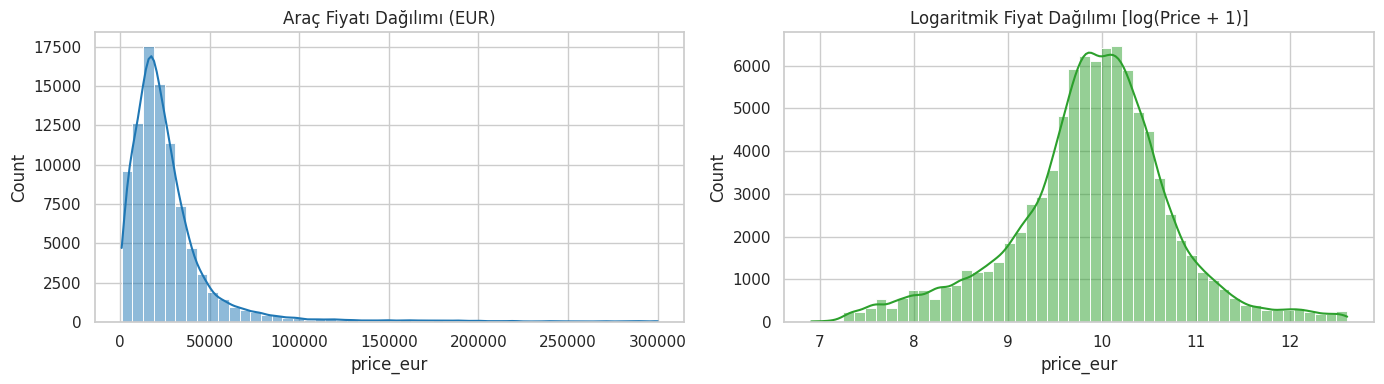

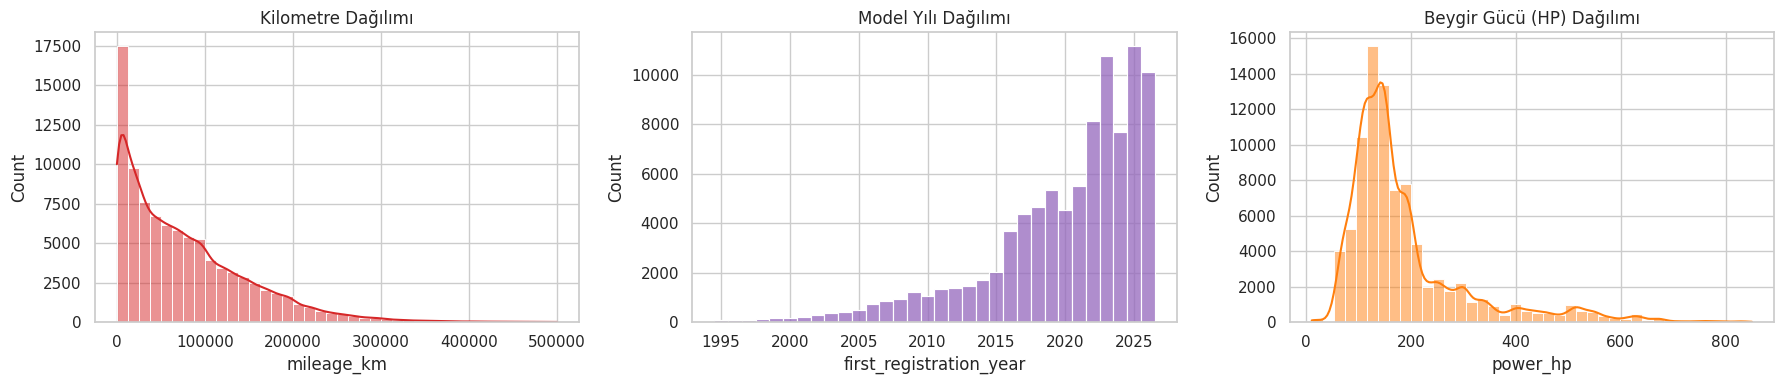

/tmp/ipykernel_11093/2775267367.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_title("Yakıt Türüne Göre Fiyat Dağılımı"); axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=25); axes[0].set_ylim(0, 150000)
/tmp/ipykernel_11093/2775267367.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_title("Vites Türüne Göre Fiyat Dağılımı"); axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20); axes[1].set_ylim(0, 150000)


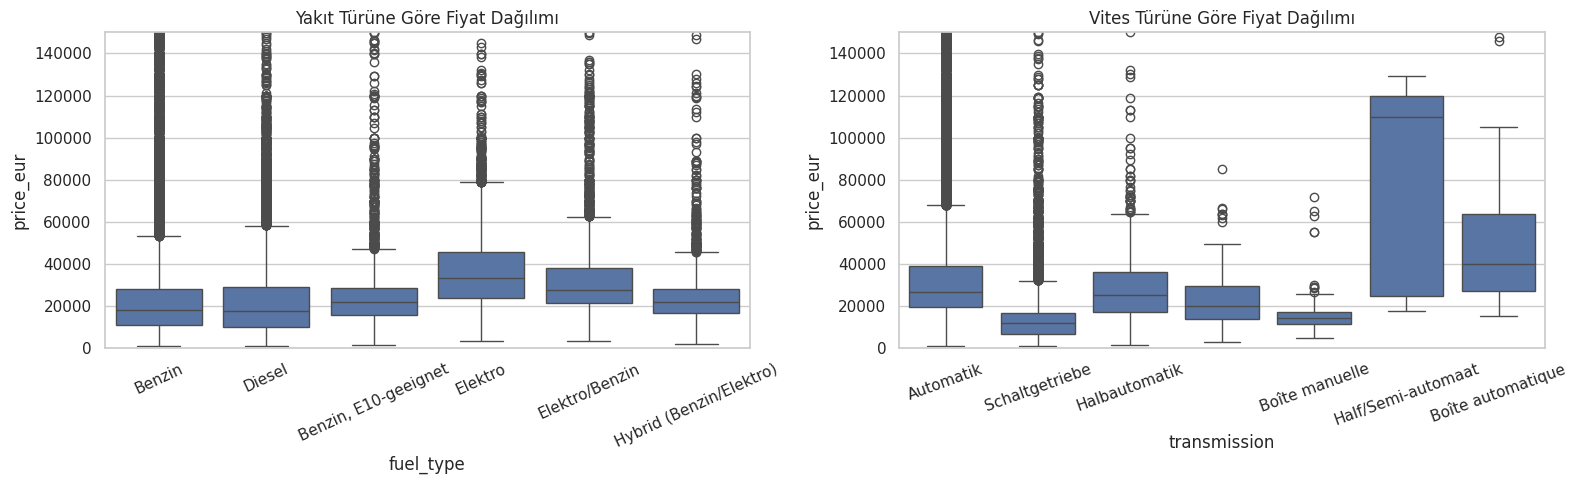

In [10]:
# 7. ADIM: Temiz ve Tekilleştirilmiş Verinin Kapsamlı Görselleştirilmesi (EDA Grafikleri)
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_clean["price_eur"], bins=50, kde=True, color="#1f77b4", ax=ax[0])
ax[0].set_title("Araç Fiyatı Dağılımı (EUR)")
sns.histplot(np.log1p(df_clean["price_eur"]), bins=50, kde=True, color="#2ca02c", ax=ax[1])
ax[1].set_title("Logaritmik Fiyat Dağılımı [log(Price + 1)]")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(df_clean["mileage_km"], bins=40, kde=True, color="#d62728", ax=axes[0]); axes[0].set_title("Kilometre Dağılımı")
sns.histplot(df_clean["first_registration_year"], bins=25, discrete=True, color="#9467bd", ax=axes[1]); axes[1].set_title("Model Yılı Dağılımı")
sns.histplot(df_clean["power_hp"].dropna(), bins=40, kde=True, color="#ff7f0e", ax=axes[2]); axes[2].set_title("Beygir Gücü (HP) Dağılımı")
plt.tight_layout(); plt.show()

top_fuels = df_clean["fuel_type"].value_counts().head(6).index
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df_clean, x="fuel_type", y="price_eur", order=top_fuels, ax=axes[0])
axes[0].set_title("Yakıt Türüne Göre Fiyat Dağılımı"); axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=25); axes[0].set_ylim(0, 150000)
sns.boxplot(data=df_clean, x="transmission", y="price_eur", ax=axes[1])
axes[1].set_title("Vites Türüne Göre Fiyat Dağılımı"); axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20); axes[1].set_ylim(0, 150000)
plt.tight_layout(); plt.show()

📊 En Çok Listelenen İlk 15 Araç Markası ve İlan Sayıları:


,İlan Sayısı
make,
Nissan,6864
MINI,6768
Mercedes-Benz,5467
MG,4610
BMW,4232
Volkswagen,4218
Fiat,4091
Skoda,4083
Kia,3982


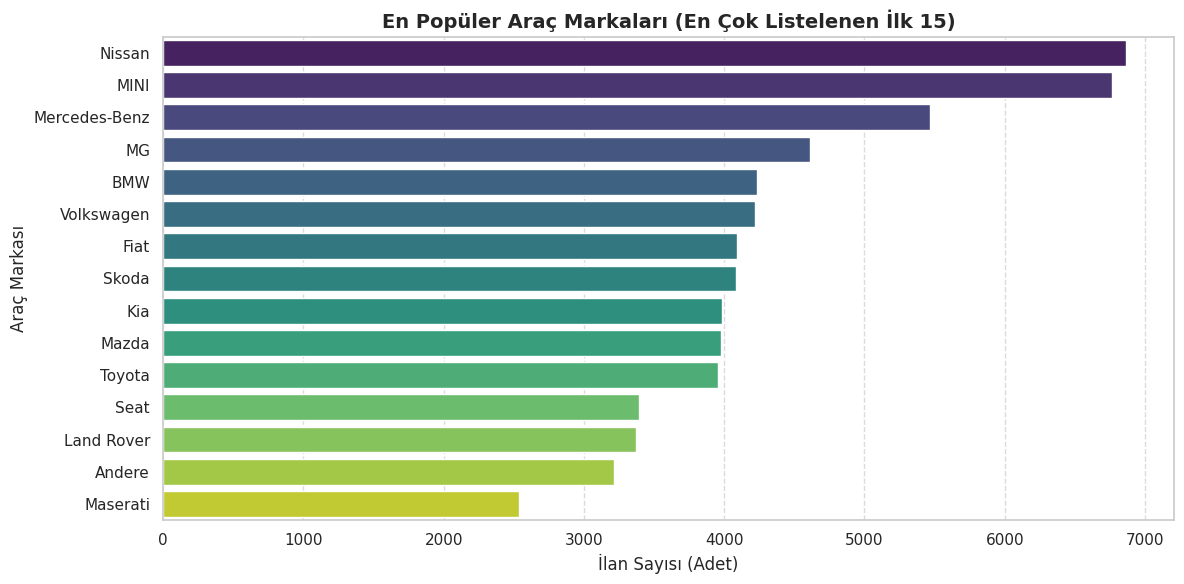

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# En çok listelenen ilk 15 markayı hesapla
top_makes = df_clean["make"].value_counts().head(15)

print("📊 En Çok Listelenen İlk 15 Araç Markası ve İlan Sayıları:")
display(top_makes.to_frame(name="İlan Sayısı"))

# Grafik çizimi
plt.figure(figsize=(12, 6))
sns.barplot(x=top_makes.values, y=top_makes.index, palette="viridis", hue=top_makes.index, legend=False)

plt.title("En Popüler Araç Markaları (En Çok Listelenen İlk 15)", fontsize=14, fontweight="bold")
plt.xlabel("İlan Sayısı (Adet)", fontsize=12)
plt.ylabel("Araç Markası", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

## Aşama 6 — Veri Bölme ve Deney Tasarımı
- **Train %60 / Validation %20 / Test %20**, `random_state=42` (tekrarlanabilirlik)
- Model karşılaştırma, hiperparametre araması (train içinde 3-fold CV) ve varyant seçimi **yalnızca train + validation** ile yapılır.
- **Test seti sadece Aşama 12'de, final model için bir kez kullanılır.**
- Train/val/test arasında satır örtüşmesi olmadığı ayrıca doğrulanmıştır.

In [11]:
# 8. ADIM: Sızıntısız Veri Bölme (Train %60 / Validation %20 / Test %20 - random_state=42)
from sklearn.model_selection import train_test_split

TARGET = "price_eur"
X = df_clean.drop(columns=[TARGET]).copy()
y = df_clean[TARGET].copy()

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42)

total_len = len(df_clean)
print(f"Train: {len(X_train):,} (%{(len(X_train)/total_len)*100:.1f}) | Val: {len(X_val):,} (%{(len(X_val)/total_len)*100:.1f}) | Test: {len(X_test):,} (%{(len(X_test)/total_len)*100:.1f})")
split_stats = pd.DataFrame({
    "Train Fiyat (€)": [y_train.mean(), y_train.median(), y_train.std()],
    "Val Fiyat (€)": [y_val.mean(), y_val.median(), y_val.std()],
    "Test Fiyat (€)": [y_test.mean(), y_test.median(), y_test.std()]
}, index=["Ortalama", "Medyan", "Std"])
display(split_stats.round(2))

Train: 54,687 (%60.0) | Val: 18,229 (%20.0) | Test: 18,230 (%20.0)


,Train Fiyat (€),Val Fiyat (€),Test Fiyat (€)
Ortalama,28292.69,28101.75,28584.94
Medyan,20945.00,20900.00,20990.00
Std,31425.08,30426.32,32035.90


In [12]:
# 9. ADIM: Güvenlik, Hedef Değişken ve %0 Örtüşme Doğrulama Kontrolü
train_tuples = set(map(tuple, X_train.fillna("MISSING").values))
val_overlap = sum(tuple(row) in train_tuples for row in X_val.fillna("MISSING").values)
test_overlap = sum(tuple(row) in train_tuples for row in X_test.fillna("MISSING").values)

print("="*65)
print("🔒 SIZINTI, HEDEF DEĞİŞKEN VE %0 ÖRTÜŞME DOĞRULAMASI")
print("="*65)
print(f"'price_eur' X_train içinde var mı? : {'❌ VAR' if 'price_eur' in X_train.columns else '✅ YOK (GÜVENLİ)'}")
print(f"'price_eur' X_val içinde var mı?   : {'❌ VAR' if 'price_eur' in X_val.columns else '✅ YOK (GÜVENLİ)'}")
print(f"'price_eur' X_test içinde var mı?  : {'❌ VAR' if 'price_eur' in X_test.columns else '✅ YOK (GÜVENLİ)'}")
print(f"X_val ile X_train ortak satır      : {val_overlap} / {len(X_val):,} (%{(val_overlap/len(X_val))*100:.2f})")
print(f"X_test ile X_train ortak satır     : {test_overlap} / {len(X_test):,} (%{(test_overlap/len(X_test))*100:.2f})")

🔒 SIZINTI, HEDEF DEĞİŞKEN VE %0 ÖRTÜŞME DOĞRULAMASI
'price_eur' X_train içinde var mı? : ✅ YOK (GÜVENLİ)
'price_eur' X_val içinde var mı?   : ✅ YOK (GÜVENLİ)
'price_eur' X_test içinde var mı?  : ✅ YOK (GÜVENLİ)
X_val ile X_train ortak satır      : 0 / 18,229 (%0.00)
X_test ile X_train ortak satır     : 0 / 18,230 (%0.00)


### Veri sözlüğü ve korelasyon analizi (sadece train verisi)

,Açıklama,Tip
make,Araç Üretici Markası,Kategorik
model,Araç Model Adı,Kategorik
first_registration_year,İlk Tescil / Model Yılı,Sayısal (1995–2026)
mileage_km,Toplam Kilometre,Sayısal (0–500.000 km)
power_hp,Motor Beygir Gücü (HP),Sayısal (11–850 HP)
fuel_type,Yakıt Türü,Kategorik
transmission,Vites Türü,Kategorik
body_type,Kasa Tipi,Kategorik
seller_country,Satıcı Ülkesi,Kategorik
price_eur,HEDEF (y): Araç Satış Fiyatı (€),Sayısal (1.000–300.000 €)


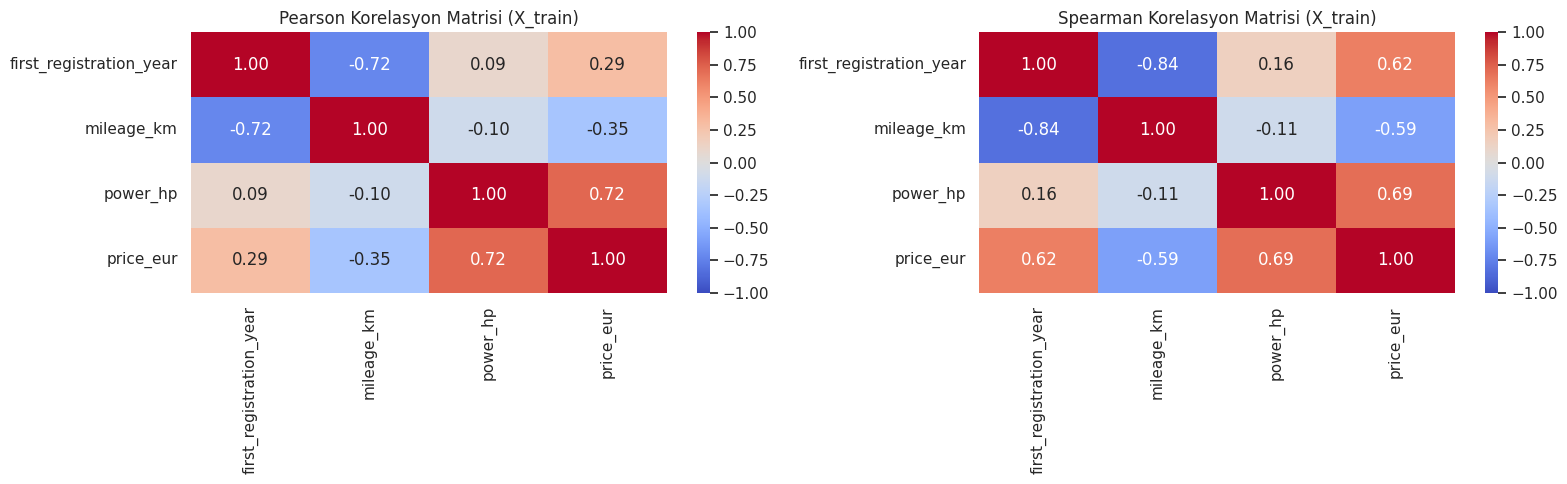

In [13]:
# 10. ADIM: Veri Sözlüğü (Data Dictionary) ve Sızıntısız Korelasyon Analizi (X_train & y_train)
data_dictionary = {
    "make": {"Açıklama": "Araç Üretici Markası", "Tip": "Kategorik"},
    "model": {"Açıklama": "Araç Model Adı", "Tip": "Kategorik"},
    "first_registration_year": {"Açıklama": "İlk Tescil / Model Yılı", "Tip": "Sayısal (1995–2026)"},
    "mileage_km": {"Açıklama": "Toplam Kilometre", "Tip": "Sayısal (0–500.000 km)"},
    "power_hp": {"Açıklama": "Motor Beygir Gücü (HP)", "Tip": "Sayısal (11–850 HP)"},
    "fuel_type": {"Açıklama": "Yakıt Türü", "Tip": "Kategorik"},
    "transmission": {"Açıklama": "Vites Türü", "Tip": "Kategorik"},
    "body_type": {"Açıklama": "Kasa Tipi", "Tip": "Kategorik"},
    "seller_country": {"Açıklama": "Satıcı Ülkesi", "Tip": "Kategorik"},
    "price_eur": {"Açıklama": "HEDEF (y): Araç Satış Fiyatı (€)", "Tip": "Sayısal (1.000–300.000 €)"}
}
display(pd.DataFrame(data_dictionary).T)

train_analysis = X_train[["first_registration_year", "mileage_km", "power_hp"]].copy()
train_analysis["price_eur"] = y_train.values
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(train_analysis.corr(method="pearson"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson Korelasyon Matrisi (X_train)")
sns.heatmap(train_analysis.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman Korelasyon Matrisi (X_train)")
plt.tight_layout(); plt.show()

## Aşama 5 (devam) — Ön İşleme Boru Hattı (Pipeline)
- Sayısal: medyan ile doldurma + StandardScaler
- Kategorik: en sık değer ile doldurma + OneHotEncoder
- Preprocessor **yalnızca X_train üzerinde fit edilir**; val/test verisinden bilgi sızmaz.

In [14]:
# 11. ADIM: Sızıntısız Ön İşleme Boru Hattı (ColumnTransformer & Pipeline)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = ["mileage_km", "first_registration_year", "power_hp"]
categorical_features = ["make", "model", "fuel_type", "transmission", "body_type", "seller_country"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

preprocessor.fit(X_train)
print("✅ Preprocessor yalnızca X_train üzerinde fit edildi.")
print("X_train dönüşüm boyutu:", preprocessor.transform(X_train).shape)
print("X_val dönüşüm boyutu  :", preprocessor.transform(X_val).shape)
print("X_test dönüşüm boyutu :", preprocessor.transform(X_test).shape)

✅ Preprocessor yalnızca X_train üzerinde fit edildi.
X_train dönüşüm boyutu: (54687, 1387)
X_val dönüşüm boyutu  : (18229, 1387)
X_test dönüşüm boyutu : (18230, 1387)


## Aşama 7 — Baseline Model
- **DummyRegressor (ortalama):** Hiçbir şey öğrenmeyen alt sınır.
- **LinearRegression:** Basit ve açıklanabilir referans model.

Validation sonuçları: Dummy R² ≈ 0, MAE ≈ 17.162 €; LinearRegression R² = 0,826, MAE ≈ 6.422 €.

In [15]:
# 12. ADIM: Baseline Modelleri (DummyRegressor & LinearRegression)
import time
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

def evaluate_regressor(name, model_pipe, X_eval, y_eval, training_time):
    preds = model_pipe.predict(X_eval)
    return {
        "Model": name,
        "R² Skoru (Başarı %)": round(r2_score(y_eval, preds), 4),
        "MAE (Ortalama Hata €)": round(mean_absolute_error(y_eval, preds), 2),
        "RMSE (Karekök Hata €)": round(root_mean_squared_error(y_eval, preds), 2),
        "Eğitim Süresi (sn)": round(training_time, 2)
    }

t0 = time.time()
dummy_pipe = Pipeline([("prep", preprocessor), ("model", DummyRegressor(strategy="mean"))])
dummy_pipe.fit(X_train, y_train)
res_dummy = evaluate_regressor("DummyRegressor (Ortalama)", dummy_pipe, X_val, y_val, time.time() - t0)

t0 = time.time()
lr_pipe = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
lr_pipe.fit(X_train, y_train)
res_lr = evaluate_regressor("LinearRegression (Baseline)", lr_pipe, X_val, y_val, time.time() - t0)

display(pd.DataFrame([res_dummy, res_lr]))

,Model,R² Skoru (Başarı %),MAE (Ortalama Hata €),RMSE (Karekök Hata €),Eğitim Süresi (sn)
0,DummyRegressor (Ortalama),-0.000,17162.35,30426.09,0.37
1,LinearRegression (Baseline),0.826,6421.53,12691.95,7.53


## Aşama 8 — İlk Model Karşılaştırması
Aynı split ve aynı preprocessor ile 5 model karşılaştırılmıştır (validation seti):

| Model | R² | MAE (€) | Süre (sn) |
|---|---|---|---|
| LightGBM | 0,9334 | 3.773,75 | 1,94 |
| XGBoost | 0,9320 | 3.987,18 | 10,19 |
| HistGradientBoosting | 0,9288 | 3.860,28 | 40,18 |
| Random Forest | 0,9144 | 4.371,14 | 23,72 |
| Ridge | 0,8193 | 6.667,04 | 1,46 |

Ağaç tabanlı boosting modelleri, doğrusal olmayan ilişkileri (yıl–km–marka etkileşimleri) yakaladığı için doğrusal modellerden belirgin şekilde daha iyidir.

✅ Ridge Regression (L2)        | R²: 0.8193 | MAE: 6,667.04 € | Süre: 1.46 sn
✅ Random Forest Regressor      | R²: 0.9144 | MAE: 4,371.14 € | Süre: 23.72 sn
✅ HistGradientBoosting         | R²: 0.9288 | MAE: 3,860.28 € | Süre: 40.18 sn


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


✅ LightGBM Regressor           | R²: 0.9334 | MAE: 3,773.75 € | Süre: 1.94 sn
✅ XGBoost Regressor            | R²: 0.9320 | MAE: 3,987.18 € | Süre: 10.19 sn


,Model,R² Skoru (Başarı %),MAE (Ortalama Hata €),RMSE (Karekök Hata €),Eğitim Süresi (sn)
0,LightGBM Regressor,0.9334,3773.75,7851.95,1.94
1,XGBoost Regressor,0.9320,3987.18,7931.81,10.19
2,HistGradientBoosting,0.9288,3860.28,8119.65,40.18
3,Random Forest Regressor,0.9144,4371.14,8901.60,23.72
4,LinearRegression (Baseline),0.8260,6421.53,12691.95,7.53
5,Ridge Regression (L2),0.8193,6667.04,12933.57,1.46
6,DummyRegressor (Ortalama),-0.0000,17162.35,30426.09,0.37


/tmp/ipykernel_11093/255190923.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plot_df, x="R² Skoru (Başarı %)", y="Model", palette="viridis", ax=axes[0])
/tmp/ipykernel_11093/255190923.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plot_df, x="MAE (Ortalama Hata €)", y="Model", palette="magma", ax=axes[1])


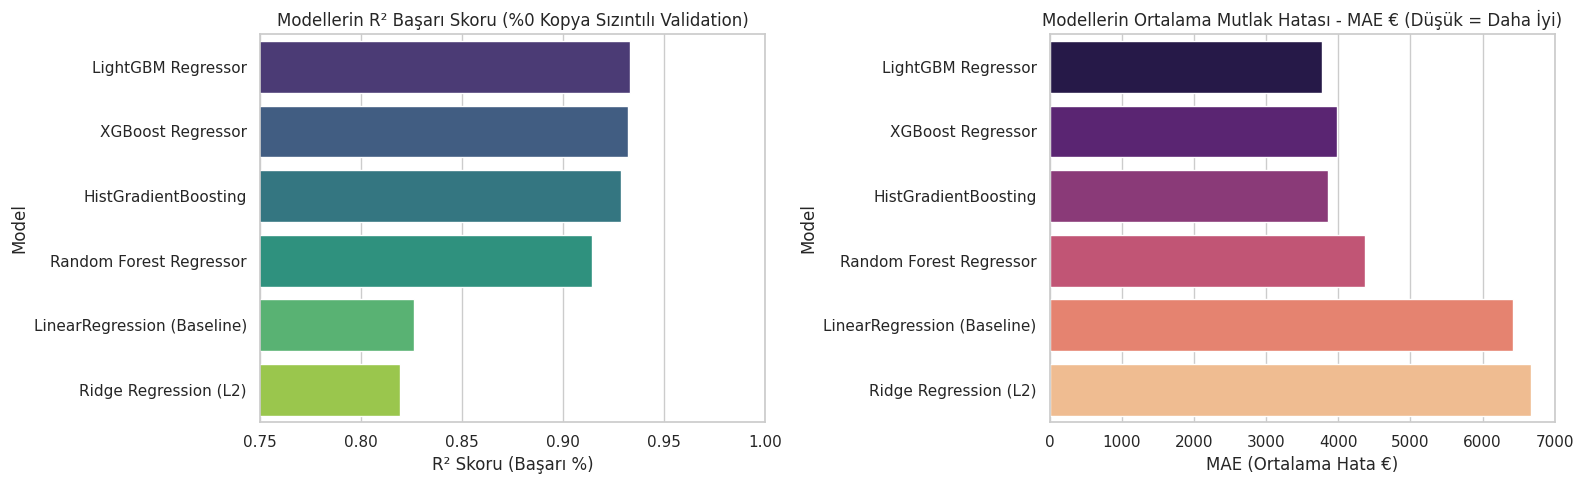

In [16]:
# 13. ADIM: 5 Güçlü Rakip Modelin Eğitimi ve Karşılaştırılması (%0 Kopya Sızıntılı Veri)
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

competitor_specs = {
    "Ridge Regression (L2)": Ridge(alpha=10.0, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=80, max_depth=18, max_features=0.3, min_samples_leaf=5, random_state=42, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=250, learning_rate=0.08, max_leaf_nodes=63, random_state=42
    ),
    "LightGBM Regressor": LGBMRegressor(
        n_estimators=300, learning_rate=0.08, num_leaves=63, random_state=42, n_jobs=-1, verbose=-1
    ),
    "XGBoost Regressor": XGBRegressor(
        n_estimators=300, learning_rate=0.08, max_depth=8, tree_method="hist", random_state=42, n_jobs=-1
    )
}

fitted_pipelines = {
    "DummyRegressor (Ortalama)": dummy_pipe,
    "LinearRegression (Baseline)": lr_pipe
}
model_results = [res_dummy, res_lr]

for name, estimator in competitor_specs.items():
    t0 = time.time()
    pipe = Pipeline([("prep", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    elapsed = time.time() - t0
    res = evaluate_regressor(name, pipe, X_val, y_val, elapsed)
    model_results.append(res)
    fitted_pipelines[name] = pipe
    print(f"✅ {name:<28} | R²: {res['R² Skoru (Başarı %)']:.4f} | MAE: {res['MAE (Ortalama Hata €)']:,.2f} € | Süre: {elapsed:.2f} sn")

results_df = pd.DataFrame(model_results).sort_values(by="R² Skoru (Başarı %)", ascending=False).reset_index(drop=True)
display(results_df)

plot_df = results_df[results_df["Model"] != "DummyRegressor (Ortalama)"].copy()
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=plot_df, x="R² Skoru (Başarı %)", y="Model", palette="viridis", ax=axes[0])
axes[0].set_title("Modellerin R² Başarı Skoru (%0 Kopya Sızıntılı Validation)")
axes[0].set_xlim(0.75, 1.0)
sns.barplot(data=plot_df, x="MAE (Ortalama Hata €)", y="Model", palette="magma", ax=axes[1])
axes[1].set_title("Modellerin Ortalama Mutlak Hatası - MAE € (Düşük = Daha İyi)")
plt.tight_layout(); plt.show()

## Aşama 9 — Aday Model Seçimi
- **Öncelikli metrik:** MAE (€), destekleyici metrik R².
- **Aday:** **XGBoost** — varsayılan ayarlarda LightGBM'e çok yakın R² vermesine rağmen hiperparametre uzayı geniş (derinlik, gamma, örnekleme) ve tuning ile iyileşme potansiyeli yüksek.
- **Güçlü rakipler:** **LightGBM** (varsayılanda en iyi R² ve en hızlı) ve **HistGradientBoosting** (en iyi 3. model). Random Forest ve doğrusal modeller belirgin şekilde geride kaldığı için rakip olarak seçilmemiştir.

## Aşama 10 — Hiperparametre Optimizasyonu (Aday: XGBoost)
- **Yöntem:** RandomizedSearchCV, **10 deneme × 3-fold CV** (sadece train), skor: R²
- **Search space:** n_estimators, learning_rate, max_depth, subsample, colsample_bytree, gamma
- En iyi model validation setinde değerlendirilir.

In [ ]:
# ADAY MODEL: XGBoost Hiperparametre Optimizasyonu (RandomizedSearchCV, 10 deneme x 3-fold CV, sadece TRAIN)
import time
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from xgboost import XGBRegressor

print("⚙️ ADAY: XGBOOST HİPERPARAMETRE OPTİMİZASYONU (10 deneme × 3-fold CV)...\n")

xgb_param_distributions = {
    "model__n_estimators": [200, 300, 500],
    "model__learning_rate": [0.05, 0.08, 0.12],
    "model__max_depth": [5, 8, 10],
    "model__subsample": [0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.8, 0.9, 1.0],
    "model__gamma": [0, 0.1, 0.2]
}

xgb_random_search = RandomizedSearchCV(
    estimator=Pipeline([("prep", preprocessor),
                        ("model", XGBRegressor(random_state=42, n_jobs=-1, tree_method="hist"))]),
    param_distributions=xgb_param_distributions,
    n_iter=10, scoring="r2", cv=3, random_state=42, n_jobs=-1, verbose=1
)

t0 = time.time()
xgb_random_search.fit(X_train, y_train)
elapsed_xgb_opt = time.time() - t0

# En iyi modeli VALIDATION seti üzerinde değerlendir (test seti kullanılmıyor)
best_xgb_model = xgb_random_search.best_estimator_
preds_xgb_opt = best_xgb_model.predict(X_val)
r2_xgb_opt = r2_score(y_val, preds_xgb_opt)
mae_xgb_opt = mean_absolute_error(y_val, preds_xgb_opt)

xgb_default = results_df.loc[results_df["Model"] == "XGBoost Regressor"].iloc[0]
print("\n================ 🏆 XGBOOST OPTİMİZASYON SONUÇLARI (Validation) =================")
print(f"En İyi Parametreler : {xgb_random_search.best_params_}")
print(f"En İyi CV R²        : {xgb_random_search.best_score_:.4f}")
print(f"Arama Süresi        : {elapsed_xgb_opt:.2f} saniye\n")
print(f"Varsayılan XGBoost  -> R²: %{xgb_default['R² Skoru (Başarı %)']*100:.2f} | MAE: {xgb_default['MAE (Ortalama Hata €)']:,.2f} €")
print(f"Optimize XGBoost    -> R²: %{r2_xgb_opt*100:.2f} | MAE: {mae_xgb_opt:,.2f} €")

## Aşama 11 — Güçlü Rakip Karşılaştırması
Rakipler, adil karşılaştırma için aday ile **aynı tuning bütçesi** (10 deneme × 3-fold CV) ve aynı preprocessor ile optimize edilir.
### 11.1 Rakip 1 — LightGBM

In [ ]:
# RAKİP 1: LightGBM Hiperparametre Optimizasyonu (Aday ile AYNI bütçe: 10 deneme x 3-fold CV)
import time
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error
from lightgbm import LGBMRegressor

print("⚙️ RAKİP 1: LIGHTGBM HİPERPARAMETRE OPTİMİZASYONU (10 deneme × 3-fold CV)...\n")

lgbm_param_distributions = {
    "model__n_estimators": [200, 300, 500],
    "model__learning_rate": [0.05, 0.08, 0.12],
    "model__num_leaves": [31, 63, 127],
    "model__max_depth": [-1, 10, 15],
    "model__subsample": [0.8, 0.9, 1.0],
    "model__subsample_freq": [1],          # subsample'ın LightGBM'de etkin olması için gerekli
    "model__colsample_bytree": [0.8, 0.9, 1.0]
}

# Not: Model n_jobs=1, arama n_jobs=2 -> iç içe paralellik kaynaklı kilitlenmeyi önler
lgbm_random_search = RandomizedSearchCV(
    estimator=Pipeline([("prep", preprocessor),
                        ("model", LGBMRegressor(random_state=42, n_jobs=1, verbose=-1))]),
    param_distributions=lgbm_param_distributions,
    n_iter=10, scoring="r2", cv=3, random_state=42, n_jobs=2, verbose=1
)

t0 = time.time()
lgbm_random_search.fit(X_train, y_train)
elapsed_lgbm_opt = time.time() - t0

best_lgbm_model = lgbm_random_search.best_estimator_
preds_lgbm_opt = best_lgbm_model.predict(X_val)

print("\n================ 🏆 LIGHTGBM OPTİMİZASYON SONUÇLARI (Validation) =================")
print(f"En İyi Parametreler : {lgbm_random_search.best_params_}")
print(f"Arama Süresi        : {elapsed_lgbm_opt:.2f} saniye")
print(f"Optimize LightGBM   -> R²: %{r2_score(y_val, preds_lgbm_opt)*100:.2f} | MAE: {mean_absolute_error(y_val, preds_lgbm_opt):,.2f} €")

### 11.2 Rakip 2 — HistGradientBoosting

In [ ]:
# RAKİP 2: HistGradientBoosting Hiperparametre Optimizasyonu (Aynı bütçe: 10 deneme x 3-fold CV)
# Not: Bu model diğerlerinden yavaştır; Colab'da birkaç dakika sürebilir.
import time
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.ensemble import HistGradientBoostingRegressor

print("⚙️ RAKİP 2: HISTGRADIENTBOOSTING HİPERPARAMETRE OPTİMİZASYONU (10 deneme × 3-fold CV)...\n")

hgb_param_distributions = {
    "model__max_iter": [200, 300, 500],
    "model__learning_rate": [0.05, 0.08, 0.12],
    "model__max_leaf_nodes": [31, 63, 127],
    "model__min_samples_leaf": [10, 20, 50],
    "model__l2_regularization": [0.0, 0.1, 1.0]
}

hgb_random_search = RandomizedSearchCV(
    estimator=Pipeline([("prep", preprocessor),
                        ("model", HistGradientBoostingRegressor(random_state=42, early_stopping=True))]),
    param_distributions=hgb_param_distributions,
    n_iter=10, scoring="r2", cv=3, random_state=42, n_jobs=2, verbose=1
)

t0 = time.time()
hgb_random_search.fit(X_train, y_train)
elapsed_hgb_opt = time.time() - t0

best_hgb_model = hgb_random_search.best_estimator_
preds_hgb_opt = best_hgb_model.predict(X_val)

print("\n================ 🏆 HISTGRADIENTBOOSTING OPTİMİZASYON SONUÇLARI (Validation) =================")
print(f"En İyi Parametreler : {hgb_random_search.best_params_}")
print(f"Arama Süresi        : {elapsed_hgb_opt:.2f} saniye")
print(f"Optimize HistGB     -> R²: %{r2_score(y_val, preds_hgb_opt)*100:.2f} | MAE: {mean_absolute_error(y_val, preds_hgb_opt):,.2f} €")

### 11.3 Karşılaştırma tablosu ve final algoritma kararı
Tuning öncesi/sonrası performans, arama maliyeti ve tahmin süresi birlikte değerlendirilir. Final algoritma validation MAE'ye göre seçilir.

In [ ]:
# GÜÇLÜ RAKİP KARŞILAŞTIRMASI: Tuning öncesi / sonrası, performans ve kaynak maliyeti (VALIDATION seti)
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

tuned_models = {
    "XGBoost Regressor":    (best_xgb_model,  elapsed_xgb_opt,  "Aday"),
    "LightGBM Regressor":   (best_lgbm_model, elapsed_lgbm_opt, "Rakip 1"),
    "HistGradientBoosting": (best_hgb_model,  elapsed_hgb_opt,  "Rakip 2"),
}

rows = []
for name, (mdl, search_time, role) in tuned_models.items():
    default_row = results_df.loc[results_df["Model"] == name].iloc[0]
    t0 = time.time()
    p = mdl.predict(X_val)
    pred_time = time.time() - t0
    rows.append({
        "Model": name,
        "Rol": role,
        "Varsayılan R²": default_row["R² Skoru (Başarı %)"],
        "Optimize R²": round(r2_score(y_val, p), 4),
        "Varsayılan MAE (€)": default_row["MAE (Ortalama Hata €)"],
        "Optimize MAE (€)": round(mean_absolute_error(y_val, p), 2),
        "Optimize RMSE (€)": round(root_mean_squared_error(y_val, p), 2),
        "Arama Süresi (sn)": round(search_time, 1),
        "Tahmin Süresi - Val (sn)": round(pred_time, 2),
    })

comparison_df = pd.DataFrame(rows).sort_values("Optimize MAE (€)").reset_index(drop=True)
display(comparison_df)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_long = comparison_df.melt(id_vars="Model", value_vars=["Varsayılan MAE (€)", "Optimize MAE (€)"],
                               var_name="Durum", value_name="MAE (€)")
sns.barplot(data=plot_long, x="MAE (€)", y="Model", hue="Durum", ax=axes[0])
axes[0].set_title("Tuning Öncesi / Sonrası MAE (Validation) — Düşük = İyi")
sns.barplot(data=comparison_df, x="Arama Süresi (sn)", y="Model", hue="Model", legend=False, ax=axes[1])
axes[1].set_title("Hiperparametre Arama Maliyeti (saniye)")
plt.tight_layout(); plt.show()

# Final algoritma: Öncelikli metrik MAE'ye göre en iyi model
best_algo_name = comparison_df.loc[0, "Model"]
best_algo_pipe = tuned_models[best_algo_name][0]
print(f"🏁 Validation MAE'ye göre seçilen final algoritma: {best_algo_name}")

### 11.4 Feature engineering varyantları (validation)
Seçilen algoritma, en iyi hiperparametreleriyle iki farklı özellik hazırlama yaklaşımında denenir:
1. `make` / `model` için **TargetEncoder** (yüksek kardinaliteli OneHot seyrekliğini azaltmak için)
2. TargetEncoder + **`fuel_type` çıkarılmış** hali (feature selection denemesi)

In [ ]:
# FEATURE ENGINEERING DENEYİ 1: Yüksek kardinaliteli 'make' ve 'model' için TargetEncoder
# Seçilen final algoritma, bulunan en iyi hiperparametreleriyle (clone) yeniden kullanılır.
import time
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder

numeric_features = ["mileage_km", "first_registration_year", "power_hp"]
high_card_features = ["make", "model"]

def build_te_preprocessor(low_card_features):
    """Sayısal: median + scaler | make/model: TargetEncoder (iç CV ile, sızıntısız) | diğer kategorikler: OneHot"""
    return ColumnTransformer(transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), numeric_features),
        ("high_cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                               ("target_enc", TargetEncoder(smooth="auto", cv=5, random_state=42))]), high_card_features),
        ("low_cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), low_card_features),
    ])

features_all = list(X_train.columns)
te_pipe = Pipeline([
    ("prep", build_te_preprocessor(["fuel_type", "transmission", "body_type", "seller_country"])),
    ("model", clone(best_algo_pipe.named_steps["model"]))
])

t0 = time.time()
te_pipe.fit(X_train[features_all], y_train)
print(f"✅ TargetEncoder varyantı eğitildi ({best_algo_name}). Süre: {time.time() - t0:.2f} sn")

In [ ]:
# FEATURE ENGINEERING DENEYİ 2: TargetEncoder + 'fuel_type' özelliği çıkarılmış (feature selection denemesi)
features_no_fuel = [c for c in X_train.columns if c != "fuel_type"]

te_nofuel_pipe = Pipeline([
    ("prep", build_te_preprocessor(["transmission", "body_type", "seller_country"])),
    ("model", clone(best_algo_pipe.named_steps["model"]))
])

t0 = time.time()
te_nofuel_pipe.fit(X_train[features_no_fuel], y_train)
print("🧹 'fuel_type' çıkarıldı. Model girdileri:", features_no_fuel)
print(f"✅ fuel_type'sız varyant eğitildi. Süre: {time.time() - t0:.2f} sn")

### 11.5 Final model seçimi
Üç varyant validation setinde karşılaştırılır; MAE'si en düşük olan final model olur.

In [ ]:
# VARYANT SEÇİMİ: Tüm varyantlar VALIDATION seti üzerinde karşılaştırılır (test seti hâlâ kullanılmadı)
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

variants = {
    f"{best_algo_name} + OneHot (tüm özellikler)":         (best_algo_pipe, features_all),
    f"{best_algo_name} + TargetEncoder (tüm özellikler)":  (te_pipe, features_all),
    f"{best_algo_name} + TargetEncoder (fuel_type yok)":   (te_nofuel_pipe, features_no_fuel),
}

variant_rows = []
for vname, (vpipe, vfeats) in variants.items():
    p = vpipe.predict(X_val[vfeats])
    variant_rows.append({
        "Varyant": vname,
        "Val R²": round(r2_score(y_val, p), 4),
        "Val MAE (€)": round(mean_absolute_error(y_val, p), 2),
        "Val RMSE (€)": round(root_mean_squared_error(y_val, p), 2),
    })

variant_df = pd.DataFrame(variant_rows).sort_values("Val MAE (€)").reset_index(drop=True)
display(variant_df)

final_variant_name = variant_df.loc[0, "Varyant"]
final_template, final_features = variants[final_variant_name]
print(f"🏁 FİNAL MODEL (Validation MAE'ye göre): {final_variant_name}")
print(f"   Kullanılan özellikler: {final_features}")

## Aşama 12 — Final Model Değerlendirmesi (Test Seti)
Final model **train + validation** verisiyle yeniden eğitilir ve daha önce hiç kullanılmamış **test setinde tek sefer** değerlendirilir.
### 12.1 Test performansı ve rezidü analizi

In [ ]:
# FİNAL MODEL: Train + Validation verisiyle yeniden eğitilir ve TEST seti üzerinde TEK SEFER değerlendirilir
import os
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

print("🔍 FİNAL MODEL DEĞERLENDİRMESİ BAŞLATILIYOR...")
final_model = clone(final_template)
final_model.fit(X_train_val[final_features], y_train_val)

test_preds_final = final_model.predict(X_test[final_features])

test_r2 = r2_score(y_test, test_preds_final)
test_mae = mean_absolute_error(y_test, test_preds_final)
test_rmse = root_mean_squared_error(y_test, test_preds_final)

print("\n================ 🎉 NİHAİ TEST SETİ PERFORMANSI ================")
print(f"Final Model           : {final_variant_name}")
print(f"Nihai R² Skoru        : %{test_r2*100:.2f}")
print(f"Nihai MAE (Hata)      : {test_mae:,.2f} €")
print(f"Nihai RMSE (Hata)     : {test_rmse:,.2f} €")
print("================================================================\n")

# Hata Analizi: Gerçek vs Tahmin ve Rezidü Dağılımı
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=y_test, y=test_preds_final, alpha=0.3, color="#1f77b4", ax=axes[0])
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "--r", linewidth=2)
axes[0].set_title("Gerçek Fiyat vs. Tahmini Fiyat (Test Seti)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Gerçek Fiyat (€)"); axes[0].set_ylabel("Tahmin Edilen Fiyat (€)")
axes[0].grid(True, linestyle="--", alpha=0.5)

residuals = y_test - test_preds_final
sns.histplot(residuals, bins=50, kde=True, color="#e377c2", ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_title("Tahmin Hatalarının (Residuals) Dağılımı", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Hata (€) [Gerçek - Tahmin]"); axes[1].set_ylabel("Sıklık (Adet)")
axes[1].grid(True, linestyle="--", alpha=0.5)
plt.tight_layout(); plt.show()

# Final modeli arayüz için kaydet
model_filename = "/content/final_model.joblib"
joblib.dump(final_model, model_filename)
print(f"💾 Final model kaydedildi: {model_filename} ({os.path.getsize(model_filename) / (1024*1024):.2f} MB)")

### 12.2 Hata analizi — iş metrikleri ve marka bazlı performans

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regresyon_metriklerini_yorumla(y_true, y_pred):
    # Temel Metrikler
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    # Yüzdesel Hatalar
    mutlak_yuzde_hatalar = np.abs((y_true - y_pred) / y_true) * 100
    mape = np.mean(mutlak_yuzde_hatalar)
    mdape = np.median(mutlak_yuzde_hatalar) # Medyan Mutlak Yüzde Hata (Uç değerlerden etkilenmez)

    # İş Hedefi: %15 Tolerans Başarısı
    tolerans_basarisi = np.mean(mutlak_yuzde_hatalar <= 15) * 100

    print("=========================================================================")
    print("      🏆 YENİ NESİL MODEL DEĞERLENDİRME VE İŞ DÜNYASI ANALİZ RAPORU      ")
    print("=========================================================================")
    print(f"1. Açıklayıcılık Gücü (R² Skoru)           : %{r2*100:.2f}")
    print(f"   -> Yorum: Modelimiz, araç fiyatlarındaki değişkenliğin %{r2*100:.2f}'sini açıklamaktadır.\n")

    print(f"2. Ortalama Mutlak Sapma (MAE)             : {mae:,.2f} €")
    print(f"3. Karekök Ortalama Hata (RMSE)            : {rmse:,.2f} €")
    print(f"   -> Yorum: RMSE ile MAE arasındaki fark ({rmse - mae:,.2f} €), modelin tekil lüks veya")
    print("             hatalı ilanlarda (uç değerlerde) yaptığı yüksek hataları temsil eder.\n")

    print(f"4. Ortalama Mutlak Yüzde Hata (MAPE)       : %{mape:.2f}")
    print(f"5. Medyan Mutlak Yüzde Hata (MdAPE)        : %{mdape:.2f}")
    print(f"   -> Yorum: Ortalama yüzde hatamız %{mape:.2f} olsa da, uç değer etkisinden arındırılmış")
    print(f"             tipik hata oranımız (MdAPE) sadece %{mdape:.2f}'dir.\n")

    print(f"6. %15 Tolerans Bandı Başarı Oranı         : %{tolerans_basarisi:.2f}")
    print(f"   -> Yorum: Test setindeki her 100 araçtan {int(tolerans_basarisi)} tanesi, gerçek değerinin")
    print("             en fazla ±%15 sapmasıyla (iş hedefimiz dahilinde) doğru tahmin edilmiştir.")
    print("=========================================================================")

    return {
        'R2': r2, 'MAE': mae, 'RMSE': rmse,
        'MAPE': mape, 'MdAPE': mdape, 'Tolerans_Basarisi': tolerans_basarisi
    }

# Nihai test seti üzerinde raporumuzu çalıştıralım
metrikler = regresyon_metriklerini_yorumla(y_test, test_preds_final)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

# 1. Test verilerini ve odaklanmış model tahminlerini tek bir DataFrame üzerinde birleştirelim
sonuc_df = pd.DataFrame({
    'Marka': X_test['make'].values,
    'Gercek_Fiyat': y_test.values,
    'Tahmin_Fiyat': test_preds_final
})

# 2. Her satır için mutlak yüzdesel hatayı ve %15 tolerans içinde olup olmadığını hesaplayalım
sonuc_df['Yuzde_Hata'] = np.abs((sonuc_df['Gercek_Fiyat'] - sonuc_df['Tahmin_Fiyat']) / sonuc_df['Gercek_Fiyat']) * 100
sonuc_df['Tolerans_Ici'] = sonuc_df['Yuzde_Hata'] <= 15

# 3. Marka bazında gruplayarak gerçek regresyon metriklerini hesaplayalım
marka_ozet = sonuc_df.groupby('Marka').apply(lambda g: pd.Series({
    'Ilan_Sayisi': int(len(g)),
    'Ortalama_Fiyat (€)': round(g['Gercek_Fiyat'].mean(), 2),
    'MAE (€)': round(mean_absolute_error(g['Gercek_Fiyat'], g['Tahmin_Fiyat']), 2),
    'MAPE (%)': round(mean_absolute_percentage_error(g['Gercek_Fiyat'], g['Tahmin_Fiyat']) * 100, 2),
    '%15_Tolerans_Basarisi (%)': round(g['Tolerans_Ici'].mean() * 100, 2)
}), include_groups=False).reset_index()

# Tip dönüşümlerini netleştirelim (Adet sütununu tam sayı yapalım)
marka_ozet['Ilan_Sayisi'] = marka_ozet['Ilan_Sayisi'].astype(int)

# 4. İlan sayısına göre çoktan aza sıralayıp ilk 20 markayı detaylı inceleyelim
marka_ozet_sorted = marka_ozet.sort_values(by='Ilan_Sayisi', ascending=False).reset_index(drop=True)

print("📊 MARKA BAZLI REGRESYON PERFORMANS ANALİZİ (İlan Sayısına Göre Sıralı Top 20):\n")
display(marka_ozet_sorted.head(20))

### 12.3 Ek analiz — fiyat segmentlerine göre (Ucuz / Orta / Pahalı) başarı
Regresyon tahminleri, train verisinden belirlenen fiyat segmentlerine çevrilerek modelin doğru segmenti bulup bulamadığı incelenmiştir.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import precision_recall_fscore_support

# DÜZELTME: Gerçek sınıflar artık hep 1 değil. Gerçek ve tahmini fiyatlar
# aynı fiyat segmentlerine (Ucuz / Orta / Pahalı) ayrılıp karşılaştırılıyor.
_ref = y_train if 'y_train' in globals() else y_test   # sınırlar eğitim verisinden
bins = np.quantile(_ref, [0, 0.33, 0.66, 1.0])
bins[0], bins[-1] = -np.inf, np.inf
seg_labels = ["Ucuz", "Orta", "Pahalı"]

eval_df = pd.DataFrame({
    'make': X_test['make'].values,
    'actual': np.asarray(y_test),
    'predicted': np.asarray(test_preds_final)
})
eval_df['actual_class'] = pd.cut(eval_df['actual'], bins=bins, labels=seg_labels).astype(str)
eval_df['predicted_class'] = pd.cut(eval_df['predicted'], bins=bins, labels=seg_labels).astype(str)

brand_metrics = []
popular_brands = eval_df['make'].value_counts()[eval_df['make'].value_counts() >= 100].index

for brand in popular_brands:
    brand_data = eval_df[eval_df['make'] == brand]
    precision, recall, f1, _ = precision_recall_fscore_support(
        brand_data['actual_class'], brand_data['predicted_class'],
        labels=seg_labels, average='macro', zero_division=0
    )
    brand_metrics.append({
        'Marka': brand,
        'İlan Sayısı (Test)': len(brand_data),
        'Hassasiyet (Precision)': round(precision, 4),
        'Duyarlılık (Recall)': round(recall, 4),
        'F1-Skoru': round(f1, 4)
    })

brand_metrics_df = pd.DataFrame(brand_metrics).sort_values(by='F1-Skoru', ascending=False).reset_index(drop=True)
display(brand_metrics_df)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# DÜZELTME: Gerçek ve tahmini fiyatlar aynı segmentlere bölünerek karşılaştırılıyor
_ref = y_train if 'y_train' in globals() else y_test
bins = np.quantile(_ref, [0, 0.33, 0.66, 1.0])
bins[0], bins[-1] = -np.inf, np.inf
seg_labels = ["Ucuz", "Orta", "Pahalı"]

y_true_cls = pd.cut(np.asarray(y_test), bins=bins, labels=seg_labels).astype(str)
y_pred_cls = pd.cut(np.asarray(test_preds_final), bins=bins, labels=seg_labels).astype(str)

cm = confusion_matrix(y_true_cls, y_pred_cls, labels=seg_labels)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=seg_labels, yticklabels=seg_labels)
plt.title("Fiyat Segmentine Göre Karışıklık Matrisi", fontsize=12, fontweight="bold")
plt.ylabel("Gerçek Segment")
plt.xlabel("Tahmin Edilen Segment")
plt.tight_layout()
plt.show()

print(classification_report(y_true_cls, y_pred_cls, labels=seg_labels, digits=4))

# ±%15 tolerans oranı (regresyon metriği olarak ayrıca)
yuzde_hata_test = np.abs((np.asarray(y_test) - np.asarray(test_preds_final)) / np.asarray(y_test))
print(f"±%15 Tolerans İçi Oran: %{np.mean(yuzde_hata_test <= 0.15)*100:.2f}")


### 12.4 Özellik önemi (Feature Importance)

In [ ]:
# ÖZELLİK ÖNEMİ (Feature Importance) — Final model
import matplotlib.pyplot as plt
import seaborn as sns

final_prep = final_model.named_steps["prep"]
final_estimator = final_model.named_steps["model"]

if hasattr(final_estimator, "feature_importances_"):
    feature_names = [n.split("__", 1)[-1] for n in final_prep.get_feature_names_out()]
    importance_df = pd.DataFrame({
        "Özellik": feature_names,
        "Önem Derecesi": final_estimator.feature_importances_
    }).sort_values(by="Önem Derecesi", ascending=False).reset_index(drop=True)

    print("📊 Final Modelin En Çok Değer Verdiği İlk 10 Özellik:")
    display(importance_df.head(10))

    plt.figure(figsize=(12, 6))
    sns.barplot(x="Önem Derecesi", y="Özellik", data=importance_df.head(15),
                palette="viridis", hue="Özellik", legend=False)
    plt.title(f"Final Model ({final_variant_name}) - En Önemli 15 Özellik", fontsize=13, fontweight="bold")
    plt.xlabel("Özellik Önem Skoru"); plt.ylabel("Özellik")
    plt.grid(axis="x", linestyle="--", alpha=0.7)
    plt.tight_layout(); plt.show()
else:
    print(f"ℹ️ {type(final_estimator).__name__} modeli feature_importances_ özelliği sunmuyor.")

### 12.5 Modelin güçlü / zayıf yönleri ve kullanım sınırları
- **Güçlü yönler:** Yaygın markalarda ve orta fiyat segmentinde düşük yüzde hata; hızlı tahmin; sızıntısız pipeline.
- **Zayıf yönler:** Lüks / nadir araçlarda yüksek mutlak hata (RMSE ile MAE arasındaki büyük fark bunu gösterir); az ilanı olan model adlarında belirsizlik.
- **Sınırlılıklar:** Hedef değişken *ilan* fiyatıdır, gerçek satış fiyatı değildir; veri belirli bir zaman dilimi ve belirli portallardan toplanmıştır; donanım paketi, hasar kaydı gibi önemli bilgiler modelde yoktur.

> ⚠️ **DOLDURULACAK:** Notebook çalıştırıldıktan sonra test sonuçlarına göre (marka tablosu, segment matrisi) bu yorumları kendi rakamlarınızla güncelleyin.

## Aşama 13 — Kullanıcı Arayüzü (Gradio)
> Arayüz hücresi, açık kalan sunucunun sonraki hücreleri kilitlememesi için **en sona** konmuştur. Arayüz, Aşama 12'de kaydedilen final modeli kullanır.

In [ ]:
import gradio as gr
import pandas as pd
import joblib

# 1. Aşama 12'de kaydedilen final modeli yükleyelim
loaded_robust_model = joblib.load("/content/final_model.joblib")

# Benzersiz değer listelerini hazırla
unique_makes = sorted(df_clean["make"].dropna().unique().tolist())
unique_fuels = sorted(df_clean["fuel_type"].dropna().unique().tolist())
unique_transmissions = sorted(df_clean["transmission"].dropna().unique().tolist())
unique_bodies = sorted(df_clean["body_type"].dropna().unique().tolist())
unique_countries = sorted(df_clean["seller_country"].dropna().unique().tolist())

# Varsayılan değerlerin listede olup olmadığını kontrol edip dinamik atama yapalım
default_make = "BMW" if "BMW" in unique_makes else unique_makes[0]
default_fuel = "Diesel" if "Diesel" in unique_fuels else unique_fuels[0]
default_trans = "Automatik" if "Automatik" in unique_transmissions else unique_transmissions[0]
default_body = "SUV" if "SUV" in unique_bodies else (unique_bodies[0] if unique_bodies else None)
default_country = "DE" if "DE" in unique_countries else unique_countries[0]

# 2. Markaya Göre Modelleri Dinamik Filtreleyen Fonksiyon
def update_models_dropdown(selected_make):
    filtered_models = sorted(df_clean[df_clean["make"] == selected_make]["model"].dropna().unique().tolist())
    default_val = filtered_models[0] if filtered_models else ""
    return gr.Dropdown(choices=filtered_models, value=default_val)

# 3. Güncellenmiş Tahmin Fonksiyonu
def predict_car_price(make, model, first_registration_year, mileage_km, power_hp, fuel_type, transmission, body_type, seller_country):
    input_df = pd.DataFrame([{
        "make": make,
        "model": model,
        "first_registration_year": int(first_registration_year),
        "mileage_km": float(mileage_km),
        "power_hp": float(power_hp),
        "fuel_type": fuel_type,
        "transmission": transmission,
        "body_type": body_type,
        "seller_country": seller_country
    }])

    # Model doğrudan preprocessor ve XGBoost'u barındıran tam bir Pipeline'dır
    prediction = loaded_robust_model.predict(input_df)[0]
    # Negatif tahminleri fiziksel sınırlandırmak amacıyla alt limit koyalım
    prediction = max(1000.0, prediction)
    return f"🚗 Tahmini Araç Değeri: {prediction:,.2f} €"

# 4. Gradio Arayüzünü Yeni Model ile Başlat
with gr.Blocks() as demo:
    gr.Markdown("# 🇪🇺 Avrupa İkinci El Araç Fiyat Tahmin Sistemi (Geliştirilmiş Sürüm)")
    gr.Markdown("**Sorun Giderildi:** Model artık One-Hot Encoding seyrekliğinden kurtarıldı. KM ve Beygir Gücü (HP) gibi fiyatı en çok etkileyen parametreler artık tahmin üzerinde baskın güce sahiptir.")

    with gr.Row():
        with gr.Column():
            make_input = gr.Dropdown(choices=unique_makes, label="Araç Markası", value=default_make)

            # Başlangıç modellerini ata
            initial_models = sorted(df_clean[df_clean["make"] == default_make]["model"].dropna().unique().tolist())
            default_model = "X3" if "X3" in initial_models else (initial_models[0] if initial_models else "")
            model_input = gr.Dropdown(choices=initial_models, label="Araç Modeli", value=default_model)

            year_input = gr.Slider(minimum=1995, maximum=2026, step=1, value=2020, label="Model Yılı")
            km_input = gr.Number(value=50000, label="Toplam Kilometre (km)")
            hp_input = gr.Number(value=190, label="Motor Gücü (HP)")

        with gr.Column():
            fuel_input = gr.Dropdown(choices=unique_fuels, label="Yakıt Türü", value=default_fuel)
            trans_input = gr.Dropdown(choices=unique_transmissions, label="Vites Türü", value=default_trans)
            body_input = gr.Dropdown(choices=unique_bodies, label="Kasa Tipi", value=default_body)
            country_input = gr.Dropdown(choices=unique_countries, label="Satıcı Ülke", value=default_country)

            predict_btn = gr.Button("🔮 Fiyatı Hesapla", variant="primary")
            output_text = gr.Textbox(label="Tahmin Sonucu", placeholder="Sonuç burada gösterilecek...")

    # Dinamik etkileşim tetikleyicisi
    make_input.change(
        fn=update_models_dropdown,
        inputs=make_input,
        outputs=model_input
    )

    predict_btn.click(
        fn=predict_car_price,
        inputs=[make_input, model_input, year_input, km_input, hp_input, fuel_input, trans_input, body_input, country_input],
        outputs=output_text
    )

demo.launch(share=True)